In [22]:
import pandas as pd
import numpy as np
import joblib
import time

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
train_data = pd.read_csv("../dataset/train_data.csv")
test_data = pd.read_csv("../dataset/test_data.csv")

print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

Training data: (35744, 2)
Testing data: (8936, 2)


In [3]:
X_train = train_data["text"]
y_train = train_data["label"]

X_test = test_data["text"]
y_test = test_data["label"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (35744,)
X_test: (8936,)
y_train: (35744,)
y_test: (8936,)


In [4]:
tfidf = joblib.load("../model/tfidf_vectorizer.pkl")

print("TF-IDF vectorizer loaded successfully!")

TF-IDF vectorizer loaded successfully!


In [5]:
X_train_tfidf = tfidf.transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
start_time = time.time()

nb_model = MultinomialNB()

nb_model.fit(
    X_train_tfidf,
    y_train
)

nb_time = time.time() - start_time

print("Naive Bayes trained successfully!")
print("Training time:", round(nb_time, 2), "seconds")
print("Training TF-IDF:", X_train_tfidf.shape)
print("Testing TF-IDF:", X_test_tfidf.shape)

Training TF-IDF: (35744, 50000)
Testing TF-IDF: (8936, 50000)


In [6]:
print("Training labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training labels:
label
0    18775
1    16969
Name: count, dtype: int64

Testing labels:
label
0    4694
1    4242
Name: count, dtype: int64


In [7]:
start_time = time.time()

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(
    X_train_tfidf,
    y_train
)

lr_time = time.time() - start_time

print("Logistic Regression trained successfully!")
print("Training time:", round(lr_time, 2), "seconds")

Logistic Regression trained successfully!
Training time: 0.59 seconds


In [8]:
lr_predictions = lr_model.predict(X_test_tfidf)

print(lr_predictions[:20])

[1 1 1 0 1 1 1 0 0 1 0 0 1 1 0 1 0 0 0 0]


In [9]:
lr_accuracy = accuracy_score(
    y_test,
    lr_predictions
)

lr_precision = precision_score(
    y_test,
    lr_predictions
)

lr_recall = recall_score(
    y_test,
    lr_predictions
)

lr_f1 = f1_score(
    y_test,
    lr_predictions
)

print("Logistic Regression Results")
print("-" * 40)
print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))

Logistic Regression Results
----------------------------------------
Accuracy : 0.9931
Precision: 0.9897
Recall   : 0.9958
F1 Score : 0.9927


In [10]:
print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=["Fake", "Real"]
    )
)

              precision    recall  f1-score   support

        Fake       1.00      0.99      0.99      4694
        Real       0.99      1.00      0.99      4242

    accuracy                           0.99      8936
   macro avg       0.99      0.99      0.99      8936
weighted avg       0.99      0.99      0.99      8936



In [11]:
start_time = time.time()

nb_model = MultinomialNB()

nb_model.fit(
    X_train_tfidf,
    y_train
)

nb_time = time.time() - start_time

print("Naive Bayes trained successfully!")
print("Training time:", round(nb_time, 2), "seconds")

Naive Bayes trained successfully!
Training time: 0.07 seconds


In [12]:
nb_predictions = nb_model.predict(X_test_tfidf)

In [13]:
nb_accuracy = accuracy_score(y_test, nb_predictions)
nb_precision = precision_score(y_test, nb_predictions)
nb_recall = recall_score(y_test, nb_predictions)
nb_f1 = f1_score(y_test, nb_predictions)

print("Naive Bayes Results")
print("-" * 40)
print("Accuracy :", round(nb_accuracy, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1 Score :", round(nb_f1, 4))

Naive Bayes Results
----------------------------------------
Accuracy : 0.9655
Precision: 0.9602
Recall   : 0.9675
F1 Score : 0.9638


In [14]:
start_time = time.time()

svm_model = LinearSVC(
    C=1.0,
    random_state=42
)

svm_model.fit(
    X_train_tfidf,
    y_train
)

svm_time = time.time() - start_time

print("Linear SVM trained successfully!")
print("Training time:", round(svm_time, 2), "seconds")

Linear SVM trained successfully!
Training time: 0.63 seconds


In [15]:
svm_predictions = svm_model.predict(
    X_test_tfidf
)

In [16]:
svm_accuracy = accuracy_score(
    y_test,
    svm_predictions
)

svm_precision = precision_score(
    y_test,
    svm_predictions
)

svm_recall = recall_score(
    y_test,
    svm_predictions
)

svm_f1 = f1_score(
    y_test,
    svm_predictions
)

print("Linear SVM Results")
print("-" * 40)
print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1 Score :", round(svm_f1, 4))

Linear SVM Results
----------------------------------------
Accuracy : 0.9983
Precision: 0.9974
Recall   : 0.9991
F1 Score : 0.9982


In [17]:
start_time = time.time()

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_tfidf,
    y_train
)

rf_time = time.time() - start_time

print("Random Forest trained successfully!")
print("Training time:", round(rf_time, 2), "seconds")

Random Forest trained successfully!
Training time: 40.82 seconds


In [18]:
rf_predictions = rf_model.predict(
    X_test_tfidf
)

In [19]:
rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

rf_precision = precision_score(
    y_test,
    rf_predictions
)

rf_recall = recall_score(
    y_test,
    rf_predictions
)

rf_f1 = f1_score(
    y_test,
    rf_predictions
)

print("Random Forest Results")
print("-" * 40)
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))

Random Forest Results
----------------------------------------
Accuracy : 0.9966
Precision: 0.9958
Recall   : 0.9972
F1 Score : 0.9965


In [20]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM",
        "Random Forest"
    ],
    
    "Accuracy": [
        lr_accuracy,
        nb_accuracy,
        svm_accuracy,
        rf_accuracy
    ],
    
    "Precision": [
        lr_precision,
        nb_precision,
        svm_precision,
        rf_precision
    ],
    
    "Recall": [
        lr_recall,
        nb_recall,
        svm_recall,
        rf_recall
    ],
    
    "F1 Score": [
        lr_f1,
        nb_f1,
        svm_f1,
        rf_f1
    ],
    
    "Training Time (sec)": [
        lr_time,
        nb_time,
        svm_time,
        rf_time
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (sec)
0,Logistic Regression,0.993062,0.989691,0.995757,0.992714,0.590439
1,Naive Bayes,0.965533,0.960225,0.967468,0.963833,0.070702
2,Linear SVM,0.998321,0.997411,0.999057,0.998233,0.632289
3,Random Forest,0.996643,0.995763,0.997171,0.996466,40.822270


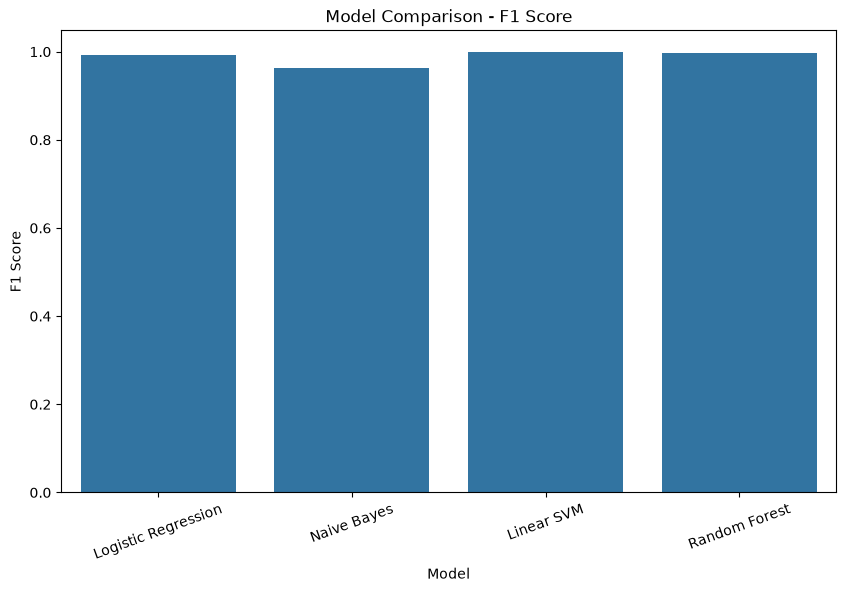

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="Model",
    y="F1 Score"
)

plt.title("Model Comparison - F1 Score")
plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.xticks(rotation=20)

plt.show()

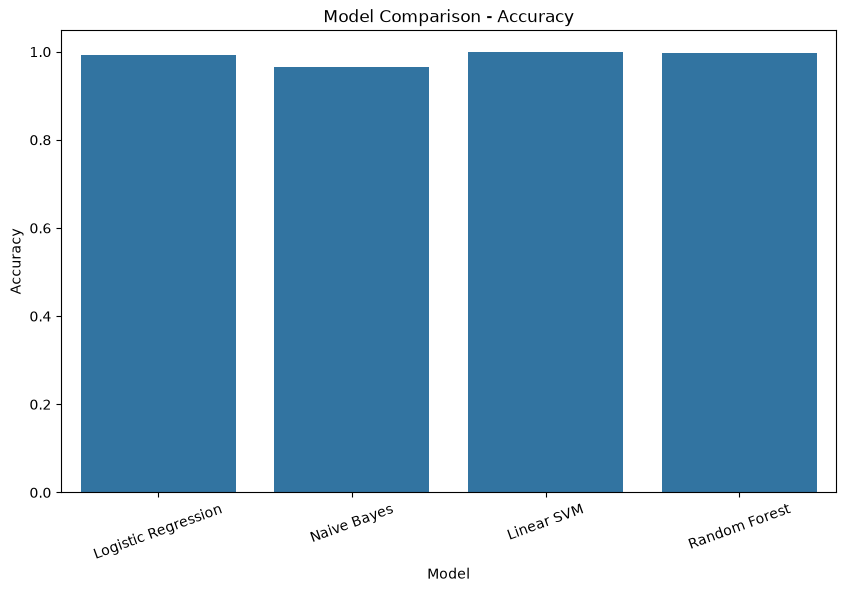

In [24]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.title("Model Comparison - Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)

plt.show()

In [25]:
results.to_csv(
    "../model/model_comparison.csv",
    index=False
)

print("Model comparison saved!")

Model comparison saved!


In [26]:
joblib.dump(
    lr_model,
    "../model/logistic_regression_model.pkl"
)

joblib.dump(
    nb_model,
    "../model/naive_bayes_model.pkl"
)

joblib.dump(
    svm_model,
    "../model/svm_model.pkl"
)

joblib.dump(
    rf_model,
    "../model/random_forest_model.pkl"
)

print("All models saved successfully!")

All models saved successfully!


In [27]:
results.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (sec)
2,Linear SVM,0.998321,0.997411,0.999057,0.998233,0.632289
3,Random Forest,0.996643,0.995763,0.997171,0.996466,40.822270
0,Logistic Regression,0.993062,0.989691,0.995757,0.992714,0.590439
1,Naive Bayes,0.965533,0.960225,0.967468,0.963833,0.070702
